<a href="https://colab.research.google.com/github/RayaRabbani129/PCVK_Ganjil_2026/blob/main/Week09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
nama = 'Raya Rabbani A'
nim = '244107020159'

print(nama)
print(nim)

Raya Rabbani A
244107020159


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

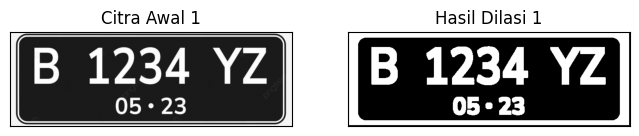

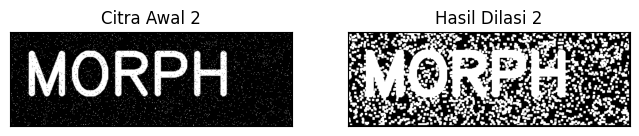

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def dilasi_citra(F, w):
    # Ukuran citra
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structuring element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

# 1. Masukkan path dari 2 citra ke dalam sebuah list
daftar_citra = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]

w = 5

# 2. Lakukan looping untuk setiap citra di dalam list
for idx, path in enumerate(daftar_citra):
    # Membaca citra dalam grayscale
    img_d = cv2.imread(path, 0)

    # Validasi apakah citra berhasil dibaca
    if img_d is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan atau gagal dimuat.")
        continue

    # Proses thresholding dan dilasi
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, w)

    # Menampilkan hasil untuk masing-masing citra
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img_d, cmap='gray')
    plt.title(f'Citra Awal {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 2, 2)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'Hasil Dilasi {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.show()

Kernel citra ke-1:
 [[1 1 1]
 [1 1 1]
 [1 1 1]]


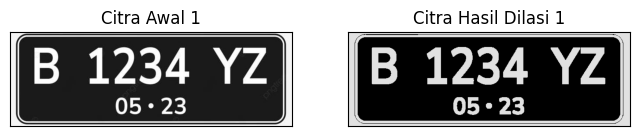

Kernel citra ke-2:
 [[1 1 1]
 [1 1 1]
 [1 1 1]]


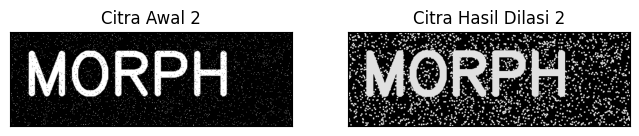

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Simpan path dari 2 citra ke dalam sebuah list
daftar_citra = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]

# 2. Lakukan looping untuk setiap citra di dalam list
for idx, path in enumerate(daftar_citra):
    # Membaca citra
    img = cv2.imread(path)

    # Validasi jika citra gagal dimuat / path salah
    if img is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan.")
        continue

    # Proses thresholding dan dilasi
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint16)
    dilasi = cv2.dilate(thresh, kernel, iterations=1)

    print(f"Kernel citra ke-{idx + 1}:\n", kernel)

    # Menampilkan hasil plot untuk masing-masing citra
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f'Citra Awal {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB))
    plt.title(f'Citra Hasil Dilasi {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.show()

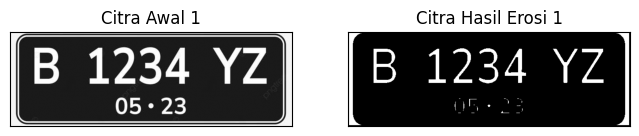

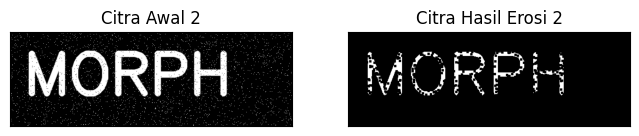

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Fungsi Erosi Tanpa Library
def erosi_citra(F, k):
    # Ukuran citra
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

# 1. Simpan path dari 2 citra ke dalam list
daftar_citra = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]

k = 5

# 2. Lakukan looping untuk setiap citra
for idx, path in enumerate(daftar_citra):
    # Membaca citra dalam mode grayscale
    img_e = cv2.imread(path, 0)

    # Validasi jika citra gagal dimuat / path salah
    if img_e is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan.")
        continue

    # Proses thresholding dan erosi manual
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    imgE = erosi_citra(thresh1, k)

    # Menampilkan hasil plot untuk masing-masing citra
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img_e, cmap='gray')
    plt.title(f'Citra Awal {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 2, 2)
    plt.imshow(imgE, cmap='gray')
    plt.title(f'Citra Hasil Erosi {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.show()

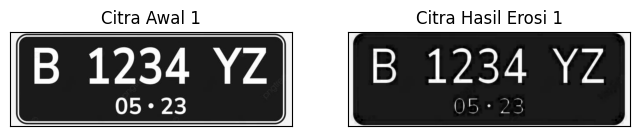

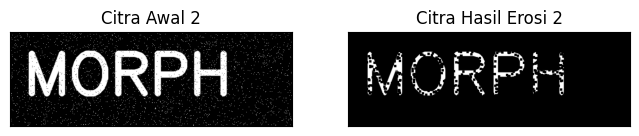

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Simpan path dari 2 citra ke dalam sebuah list
daftar_citra = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]

# 2. Tentukan kernel untuk erosi
kernel = np.ones((5, 5), np.uint8)

# 3. Lakukan looping untuk setiap citra di dalam list
for idx, path in enumerate(daftar_citra):
    # Membaca citra
    img = cv2.imread(path)

    # Validasi jika citra gagal dimuat / path salah
    if img is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan.")
        continue

    # Proses erosi menggunakan library OpenCV
    erosion = cv2.erode(img, kernel, iterations=1)

    # Menampilkan hasil plot untuk masing-masing citra
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f'Citra Awal {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB))
    plt.title(f'Citra Hasil Erosi {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.show()

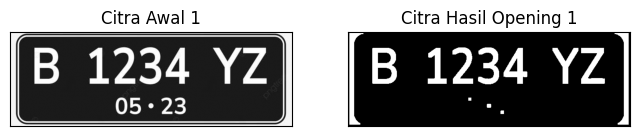

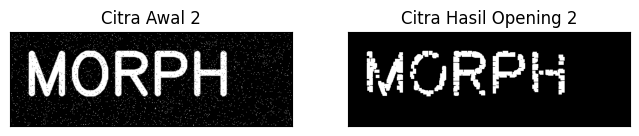

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# (Pastikan fungsi erosi_citra dan dilasi_citra sudah didefinisikan sebelumnya)

# 1. Simpan path dari 2 citra ke dalam sebuah list
daftar_citra = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]

k = 7

# 2. Lakukan looping untuk setiap citra di dalam list
for idx, path in enumerate(daftar_citra):
    # Membaca citra dalam mode grayscale
    img_o = cv2.imread(path, 0)

    # Validasi jika citra gagal dimuat / path salah
    if img_o is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan.")
        continue

    # Proses thresholding dan operasi opening (erosi lalu dilasi)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    imgO = dilasi_citra(erosi_citra(thresho, k), k)

    # Menampilkan hasil plot untuk masing-masing citra
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img_o, cmap='gray')
    plt.title(f'Citra Awal {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 2, 2)
    plt.imshow(imgO, cmap='gray')
    plt.title(f'Citra Hasil Opening {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.show()

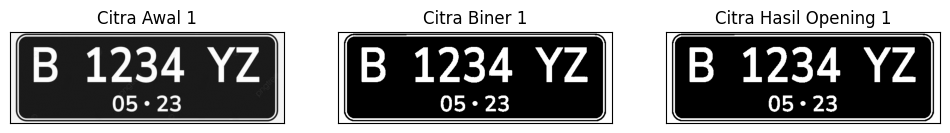

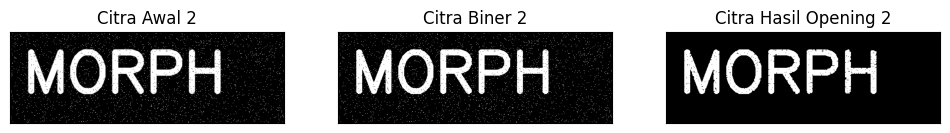

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Simpan path dari 2 citra ke dalam sebuah list
daftar_citra = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]

# 2. Tentukan kernel untuk operasi opening
kernel = np.ones((3, 3), np.uint8)

# 3. Lakukan looping untuk setiap citra di dalam list
for idx, path in enumerate(daftar_citra):
    # Membaca citra dalam mode grayscale
    img = cv2.imread(path, 0)

    # Validasi jika citra gagal dimuat / path salah
    if img is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan.")
        continue

    # Proses thresholding dan morphological opening menggunakan library OpenCV
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    # Menampilkan hasil plot (3 kolom) untuk masing-masing citra
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title(f'Citra Awal {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 3, 2)
    plt.imshow(thresh, cmap='gray')
    plt.title(f'Citra Biner {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 3, 3)
    plt.imshow(openn, cmap='gray')
    plt.title(f'Citra Hasil Opening {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.show()

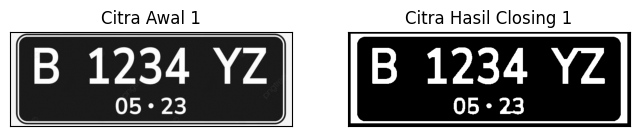

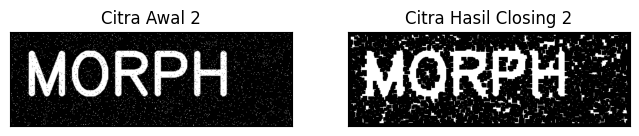

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# (Pastikan fungsi dilasi_citra dan erosi_citra sudah didefinisikan sebelumnya)

# 1. Simpan path dari 2 citra ke dalam sebuah list
daftar_citra = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]

k = 7

# 2. Lakukan looping untuk setiap citra di dalam list
for idx, path in enumerate(daftar_citra):
    # Membaca citra dalam mode grayscale
    img_c = cv2.imread(path, 0)

    # Validasi jika citra gagal dimuat / path salah
    if img_c is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan.")
        continue

    # Proses thresholding dan operasi closing (dilasi terlebih dahulu, lalu erosi)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    imgC = erosi_citra(dilasi_citra(threshc, k), k)

    # Menampilkan hasil plot untuk masing-masing citra
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img_c, cmap='gray')
    plt.title(f'Citra Awal {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(1, 2, 2)
    plt.imshow(imgC, cmap='gray')
    plt.title(f'Citra Hasil Closing {idx + 1}')
    plt.xticks([]), plt.yticks([])

    plt.show()

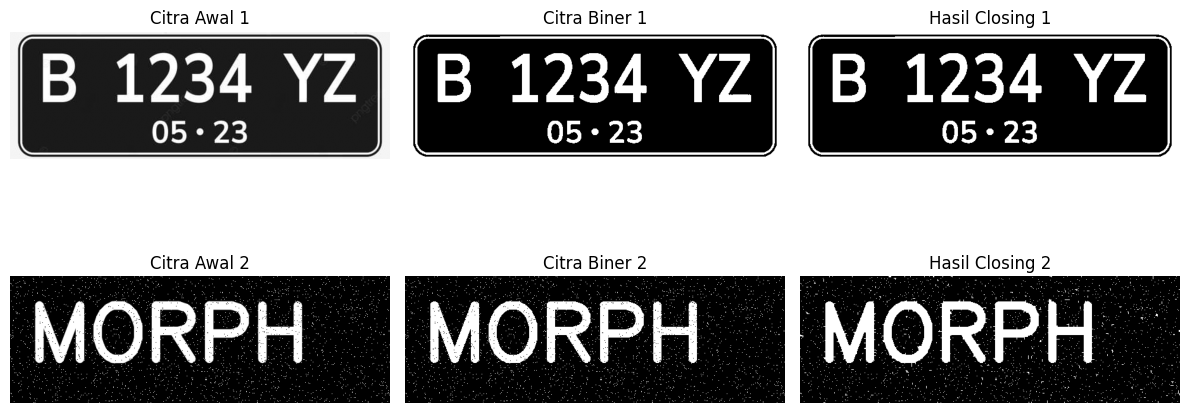

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Operasi Closing Square 3x3 dengan Menggunakan Library Morphologi

path_gambar = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]
kernel = np.ones((3, 3), np.uint8)
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    if img is None:
        print(f"Peringatan: Citra pada path '{path}' tidak ditemukan.")
        continue
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
    closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    tampilan = [
        (img, f'Citra Awal {i+1}'),
        (thresh, f'Citra Biner {i+1}'),
        (closs, f'Hasil Closing {i+1}')
    ]

    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

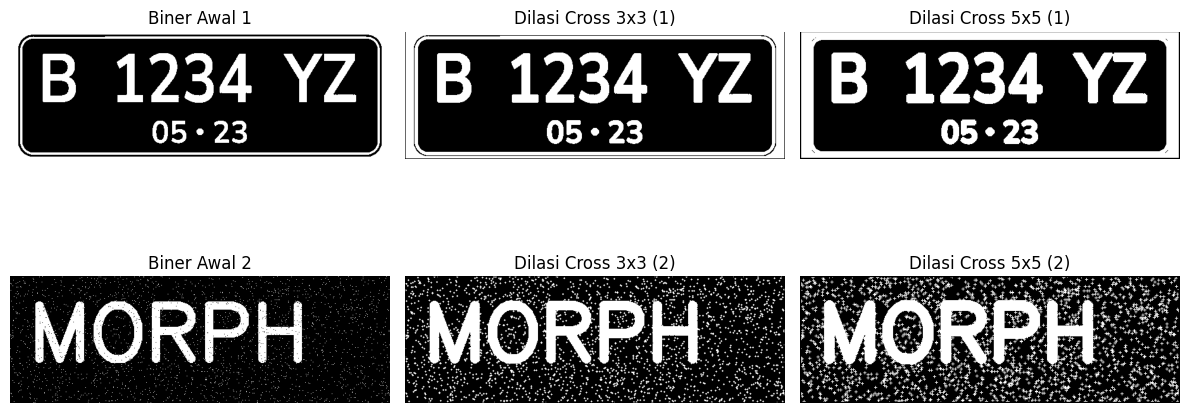

In [18]:
# Operasi Dilasi Structuring Element berbentuk Cross 3 x 3 dan 5 x 5

# Fungsi Dilasi Manual (Menerima Matriks SED Bebas)
def dilasi_citra(F, SED):
    p, q = F.shape
    w = SED.shape[0]
    constant = (w - 1) // 2
    imgD = np.zeros((p, q), dtype=np.uint8)

    for i in range(constant, p - constant):
        for j in range(constant, q - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            imgD[i, j] = np.max(temp * SED)
    return imgD

# Matriks Structuring Element Cross 3x3 dan 5x5
SED_cross3 = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

SED_cross5 = np.array([
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 1, 1],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0]
], dtype=np.uint8)

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Memproses dengan Cross 3x3 dan Cross 5x5
    dilasi_3 = dilasi_citra(thresh, SED_cross3)
    dilasi_5 = dilasi_citra(thresh, SED_cross5)

    # Menampilkan perbandingan per baris
    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (dilasi_3, f'Dilasi Cross 3x3 ({i+1})'),
        (dilasi_5, f'Dilasi Cross 5x5 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

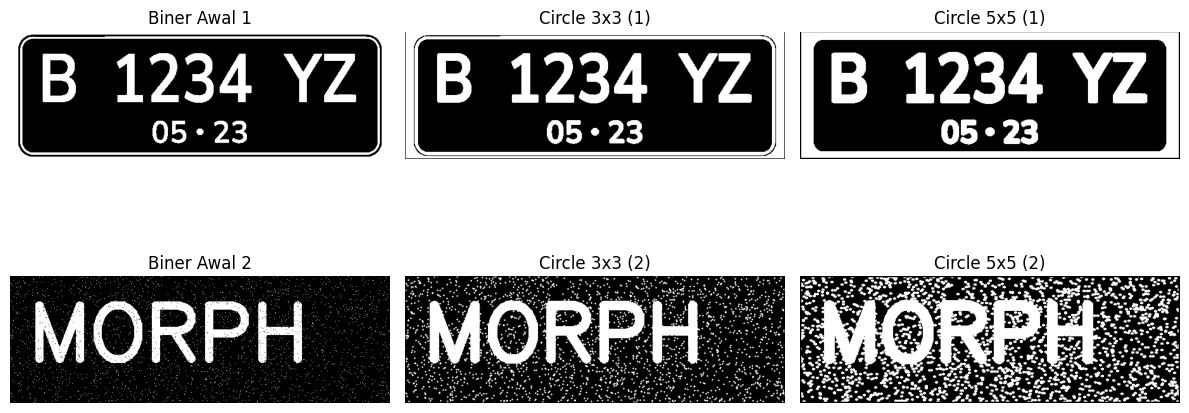

In [20]:
# Operasi Dilasi Structuring Element berbentuk Circular 3 x 3 dan 5 x 5

# Fungsi Dilasi Circular Manual
def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structuring Element berbentuk Circular
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi Manual
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            imgD[i, j] = np.max(temp * SED)
    return imgD

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Dilasi Circular dengan ukuran 3x3 dan 5x5
    dilasi_c3 = dilasi_circular(thresh, 3)
    dilasi_c5 = dilasi_circular(thresh, 5)

    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (dilasi_c3, f'Circle 3x3 ({i+1})'),
        (dilasi_c5, f'Circle 5x5 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')
plt.tight_layout()
plt.show()

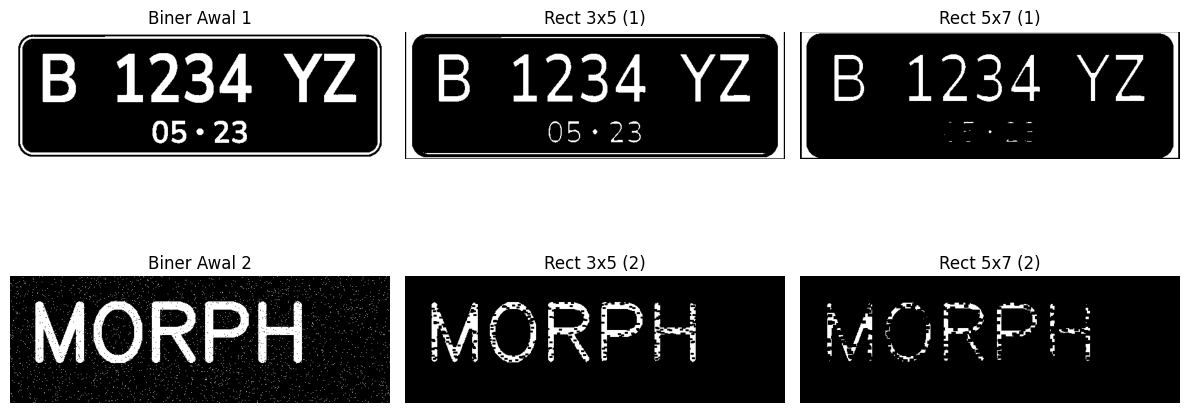

In [21]:
# Operasi Erosi Structuring Element berbentuk Rectangle 3 x 5 dan 5 x 7

# Fungsi Erosi Rectangle Manual
def erosi_rectangle(F, p, l):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)

    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    # Proses Erosi Manual
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1 : i + constant1 + 1, j - constant2 : j + constant2 + 1]
            imgE[i, j] = np.min(temp * SE)

    return imgE

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Erosi Rectangle: 3x5 (p=5, l=3) dan 5x7 (p=7, l=5)
    erosi_3x5 = erosi_rectangle(thresh, p=5, l=3)
    erosi_5x7 = erosi_rectangle(thresh, p=7, l=5)


    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (erosi_3x5, f'Rect 3x5 ({i+1})'),
        (erosi_5x7, f'Rect 5x7 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

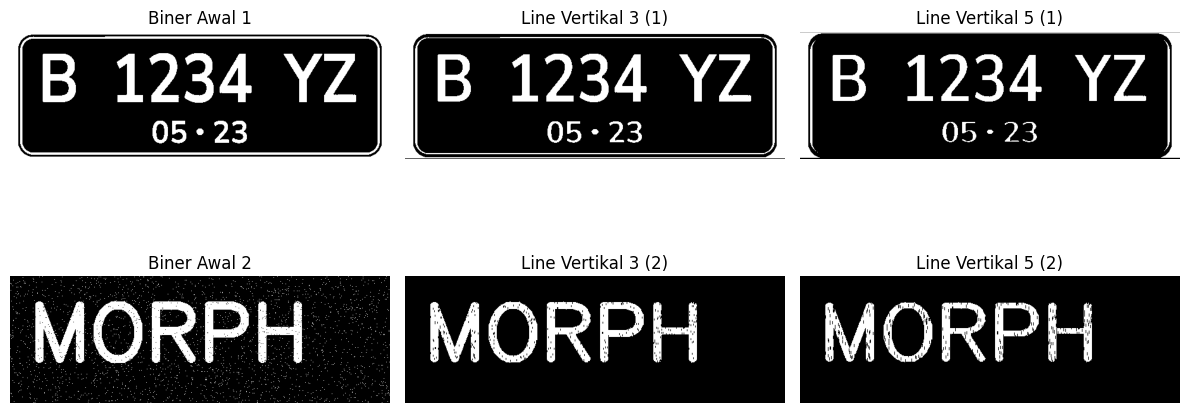

In [22]:
# Operasi Erosi Structuring Element berbentuk Line vertikal 3 dan 5

# Fungsi Erosi Line Vertikal Manual
def erosi_line_vertikal(F, k):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)

    # SE berbentuk Line Vertikal (lebar = 1, tinggi = k)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (1, k))
    constant = (k - 1) // 2

    # Proses Erosi Manual
    for i in range(constant, m - constant):
        for j in range(0, n):
            # Slicing vertikal sepanjang k dan horizontal sebesar 1 piksel
            temp = F[i - constant : i + constant + 1, j : j + 1]
            imgE[i, j] = np.min(temp * SE)
    return imgE

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/platnomor.jpg',
    '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Erosi Line Vertikal ukuran 3 dan 5
    erosi_v3 = erosi_line_vertikal(thresh, k=3)
    erosi_v5 = erosi_line_vertikal(thresh, k=5)

    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (erosi_v3, f'Line Vertikal 3 ({i+1})'),
        (erosi_v5, f'Line Vertikal 5 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

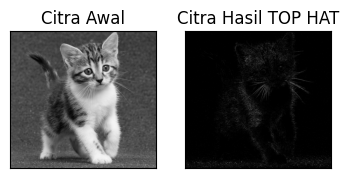

In [23]:
# Transformasi Top-hat dengan structuring element 3 × 3

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/kitten01 (1).jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

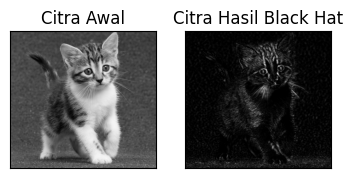

In [24]:
# Transformasi Black-hat dengan structuring element 3 × 3.

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/kitten01 (1).jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

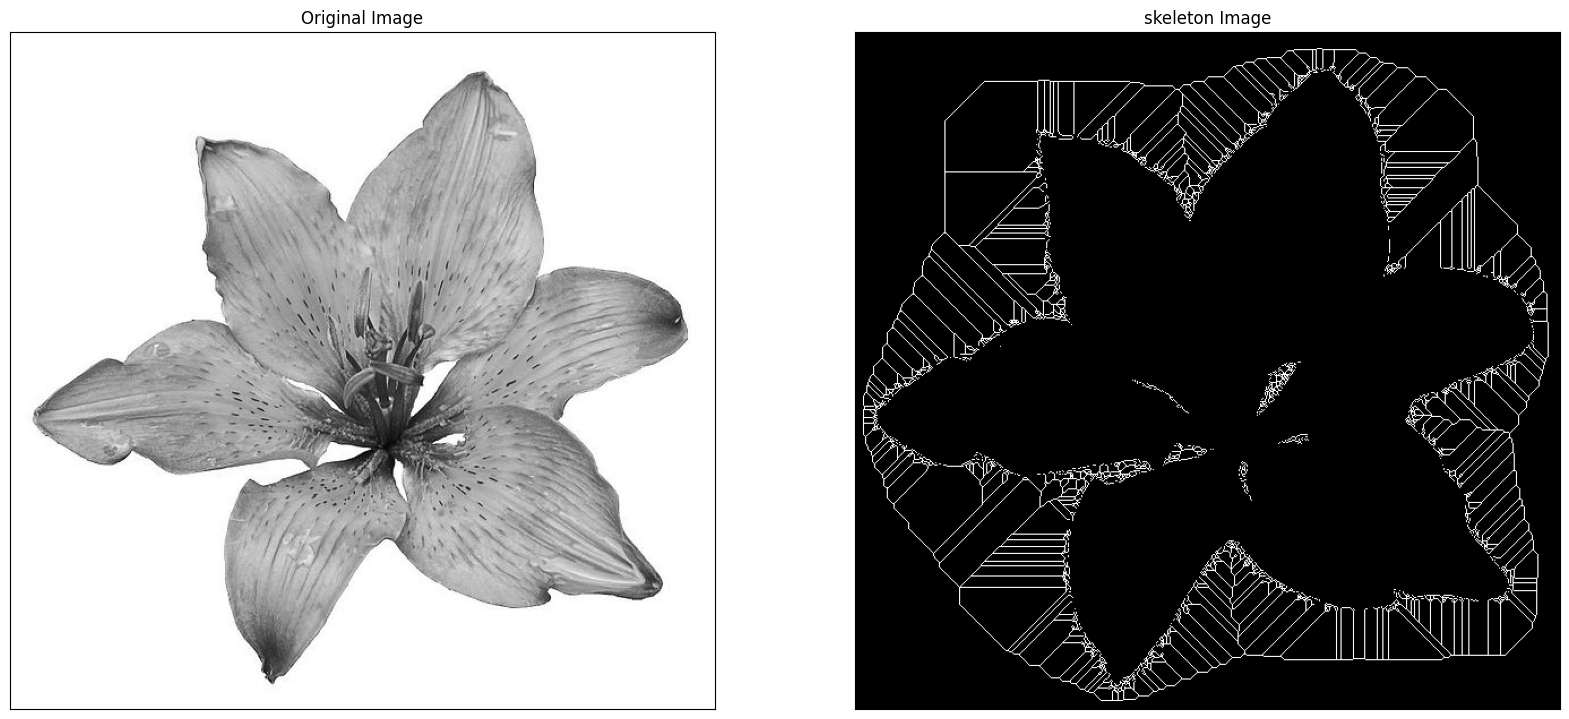

In [25]:
# Skeleton pada Citra Biner

import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/lily.jpg',0)
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))

plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

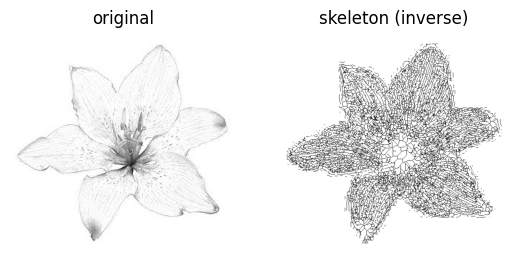

In [26]:
# Skeleton pada Citra Hasil Inversi

from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use :
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

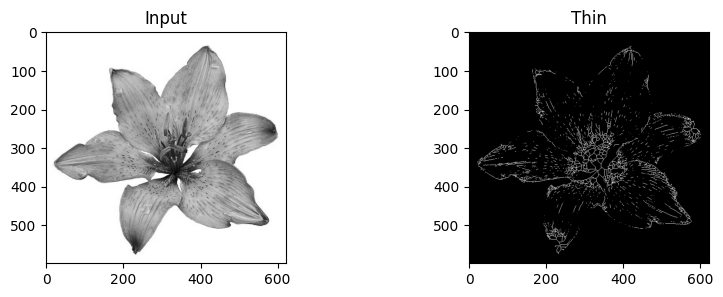

In [27]:
# Thinning dengan morphology.thin()

from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()